In [36]:
import numpy as np
import cupy as cp
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

import skimage
from skimage.color import rgb2lab, lab2rgb

from scipy.interpolate import BSpline, make_interp_spline

from scipy.optimize import minimize
from scipy.optimize import dual_annealing
from scipy.optimize import least_squares
from scipy.optimize import basinhopping

from numpy.random import random
from numpy.random import rand

from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

import time

In [50]:
cp.cuda.Device(1)

<CUDA Device 1>

In [37]:
md_path = 'nbi'
model = keras.models.load_model(md_path)

In [38]:
print(model.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 24)                96        
                                                                 
 dense_1 (Dense)             (None, 24)                600       
                                                                 
 dense_2 (Dense)             (None, 3)                 75        
                                                                 
Total params: 771
Trainable params: 771
Non-trainable params: 0
_________________________________________________________________
None


In [39]:
weight_file = 'cap5.hdf5'
model.load_weights(weight_file)
weights = model.get_weights()

In [40]:
np.save('weight_nbi0.npy', weights[0])
np.save('weight_nbi1.npy', weights[1])
np.save('weight_nbi2.npy', weights[2])
np.save('weight_nbi3.npy', weights[3])
np.save('weight_nbi4.npy', weights[4])
np.save('weight_nbi5.npy', weights[5])

In [61]:
nbi_weights = []
nbi_weights.append(np.load('weight_nbi0.npy'))
nbi_weights.append(np.load('weight_nbi1.npy'))
nbi_weights.append(np.load('weight_nbi2.npy'))
nbi_weights.append(np.load('weight_nbi3.npy'))
nbi_weights.append(np.load('weight_nbi4.npy'))
nbi_weights.append(np.load('weight_nbi5.npy'))

In [65]:
def sToneCurve(frame):
    look_up_table = np.zeros((256,1), dtype = 'uint8')
    for i in range(256):
        look_up_table[i][0] = 255 * (np.sin(np.pi * (i/255 - 1/2)) + 1) / 2
    return cv2.LUT(frame, look_up_table)

def to_nbi(img):
    
    img_shape = img.shape
    
    tar_img = img.reshape(-1,3) / 255
    
    tar_img = np.dot(tar_img, nbi_weights[0]) + nbi_weights[1]
    tar_img = np.dot(tar_img, nbi_weights[2]) + nbi_weights[3]
    tar_img = np.dot(tar_img, nbi_weights[4]) + nbi_weights[5]

#     tar_img = cp.array(tar_img)
#     tar_img = cp.dot(tar_img, nbi_weights[0]) + nbi_weights[1]
#     tar_img = cp.dot(tar_img, nbi_weights[2]) + nbi_weights[3]
#     tar_img = cp.dot(tar_img, nbi_weights[4]) + nbi_weights[5]
    
    tar_img = tar_img * 255

    tar_img = tar_img.reshape(img_shape)
    
    tar_img[tar_img>255] = 255
    tar_img[tar_img<0] = 0
    
    tar_img = tar_img.astype('uint8')
    
    tar_img = sToneCurve(tar_img)
    
    return tar_img

In [66]:
img = cv2.imread('img_cap3.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

t0 = time.time()
nbi = to_nbi(img)
print(time.time() - t0)

0.5729329586029053


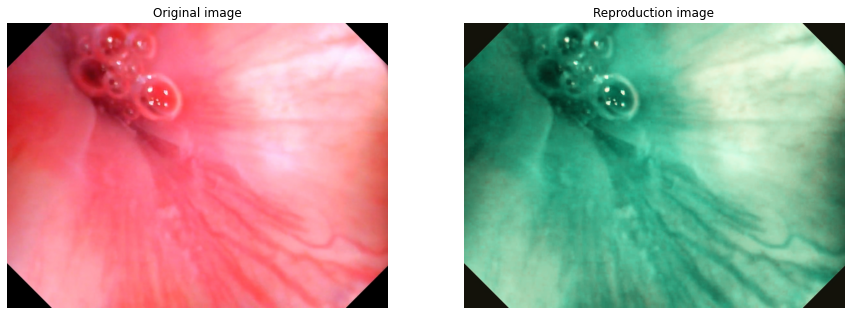

In [67]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(nbi)
plt.title('Reproduction image')
plt.axis('off')

plt.show()

In [4]:
def md_trans(img):
    tar_img = np.dot(img, weights[0]) + weights[1]
    tar_img = np.dot(tar_img, weights[2]) + weights[3]
    tar_img = np.dot(tar_img, weights[4]) + weights[5]
    return tar_img

def predict(img):
    
    img_shape = img.shape
    
#     sim_nbis = md_trans(img.reshape(-1,3) / 255) * 255
    sim_nbis = model.predict(img.reshape(-1,3) / 255, batch_size = img_shape[0] * img_shape[1], verbose=0) * 255
    
    sim_nbis = sim_nbis.reshape(img_shape)
    
    sim_nbis[sim_nbis>255] = 255
    sim_nbis[sim_nbis<0] = 0
    
    return sim_nbis.astype('uint8')

ValueError: Layer count mismatch when loading weights from file. Model expected 2 layers, found 3 saved layers.

In [5]:
def Video2Video(video_file, tar_file):

    msg = ''
    
    vidcap = cv2.VideoCapture(video_file)
    
    if vidcap != None:
        
        if vidcap.isOpened():
            success = True
        else:
            msg = 'Video Open Fail'
            success = False    
    else:
        msg = 'VideoCapture None'
        success = False
        
    if success is False:
        return [False, msg, 0]
    
    # 建立資料夾
    tar_path = os.path.dirname(os.path.abspath(tar_file))
    
    if not os.path.isdir(tar_path):
        try:
            os.makedirs(tar_path)
        # 檔案已存在的例外處理
        except FileExistsError:
            print("檔案已存在。")
     
    # 開始轉換
    index = 0
    count = 0
    
    out_video = None
    
    while success:
       
        read_suc, image = vidcap.read()
        
        if read_suc is False:
            break
        
        h,w,c = image.shape

        pred_img = predict(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        pred_img = cv2.cvtColor(pred_img, cv2.COLOR_RGB2BGR)

        tar_img = np.zeros((h, w*2, c))
        tar_img[:,:w,:] = image
        tar_img[:,w:2*w,:] = pred_img

        tar_img = tar_img.astype('uint8')

        if out_video is None:
            fourcc = cv2.VideoWriter_fourcc(*'XVID')
            out_video = cv2.VideoWriter(tar_file, fourcc, 30.0, (tar_img.shape[1], tar_img.shape[0]))

        out_video.write(tar_img)
        
        count += 1
        index += 1 
        
    if out_video is not None:
        out_video.release()
        
    vidcap.release()
    
    if success:
        msg = 'success'
    
    return [success, msg, count]

In [6]:
src_file = r'C:\Users\Tony\Desktop\TEST\001_20210514_北榮IRB_20200731_P000000008_E000000008_S000000008_V000000008.mp4'
tar_file = r'C:\Users\Tony\Desktop\TEST\001_20210514_北榮IRB_20200731_P000000008_E000000008_S000000008_V000000008____.mp4'

Video2Video(src_file, tar_file)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

1861
1862
1863
1864
1865
1866
1867
1868
1869
1870
1871
1872
1873
1874
1875
1876
1877
1878
1879
1880
1881
1882
1883
1884
1885
1886
1887
1888
1889
1890
1891
1892
1893
1894
1895
1896
1897
1898
1899
1900
1901
1902
1903
1904
1905
1906
1907
1908
1909
1910
1911
1912
1913
1914
1915
1916
1917
1918
1919
1920
1921
1922
1923
1924
1925
1926
1927
1928
1929
1930
1931
1932
1933
1934
1935
1936
1937
1938
1939
1940
1941
1942
1943
1944
1945
1946
1947
1948
1949
1950
1951
1952
1953
1954
1955
1956
1957
1958
1959
1960
1961
1962
1963
1964
1965
1966
1967
1968
1969
1970
1971
1972
1973
1974
1975
1976
1977
1978
1979
1980
1981
1982
1983
1984
1985
1986
1987
1988
1989
1990
1991
1992
1993
1994
1995
1996
1997
1998
1999
2000
2001
2002
2003
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
2021
2022
2023
2024
2025
2026
2027
2028
2029
2030
2031
2032
2033
2034
2035
2036
2037
2038
2039
2040
2041
2042
2043
2044
2045
2046
2047
2048
2049
2050
2051
2052
2053
2054
2055
2056
2057
2058
2059
2060


[True, 'success', 3390]

In [25]:
predict(image.reshape(-1,3))

array([[46, 43, 33],
       [46, 43, 33],
       [46, 43, 33],
       ...,
       [46, 43, 33],
       [46, 43, 33],
       [46, 43, 33]], dtype=uint8)

In [ ]:
# Test P

In [29]:
model.predict(image.reshape(-1,3), batch_size = image.shape[0] * image.shape[1])

1/1 [==============================] - 0s 39ms/step


array([[0.18315226, 0.16882163, 0.13044159],
       [0.18315226, 0.16882163, 0.13044159],
       [0.18315226, 0.16882163, 0.13044159],
       ...,
       [0.18315226, 0.16882163, 0.13044159],
       [0.18315226, 0.16882163, 0.13044159],
       [0.18315226, 0.16882163, 0.13044159]], dtype=float32)

In [10]:
import os
from os import listdir
from os.path import isfile, isdir, join
from os import walk
import pandas as pd

In [11]:
tar_path = r'G:\CCUMedicalData\capsule_dump'
tar_ext = 'mp4'

In [12]:
def filter_ext(files, tar_ext):
    
    tar_files = []
    
    for file in files:
        
        file_ext = os.path.splitext(file)[-1][1:].lower()
        
        if file_ext == tar_ext:
            tar_files.append(file)
        
    return tar_files
    
def get_all_ext_list(tar_path, tar_ext):
    
    all_tar_files = []
    
    for root, dirs, files in walk(tar_path):
        
        tar_files = filter_ext(files, tar_ext.lower())

        if len(tar_files) == 0:
            continue
            
        tar_files = [join(root, file) for file in tar_files]
            
        all_tar_files = all_tar_files + tar_files
        
    return all_tar_files

In [13]:
res_files = get_all_ext_list(tar_path, tar_ext)
res_files

['G:\\CCUMedicalData\\capsule_dump\\000_20210514_北榮IRB_20200731_P000000007_E000000007_S000000007_V000000007.mp4',
 'G:\\CCUMedicalData\\capsule_dump\\001_20210514_北榮IRB_20200731_P000000008_E000000008_S000000008_V000000008.mp4',
 'G:\\CCUMedicalData\\capsule_dump\\002_20210514_北榮IRB_20200731_P000000009_E000000009_S000000009_V000000009.mp4',
 'G:\\CCUMedicalData\\capsule_dump\\003_20210514_北榮IRB_20201016_P000000010_E000000010_S000000010_V000000010.mp4',
 'G:\\CCUMedicalData\\capsule_dump\\004_20210514_北榮IRB_20201016_P000000011_E000000011_S000000011_V000000011.mp4',
 'G:\\CCUMedicalData\\capsule_dump\\005_20210514_北榮IRB_20201023_P000000014_E000000014_S000000014_V000000013.mp4',
 'G:\\CCUMedicalData\\capsule_dump\\006_20210514_北榮IRB_20201023_P000000015_E000000015_S000000015_V000000014.mp4',
 'G:\\CCUMedicalData\\capsule_dump\\007_20210514_北榮IRB_20201030_P000000016_E000000016_S000000016_V000000015.mp4',
 'G:\\CCUMedicalData\\capsule_dump\\008_20210514_北榮IRB_20201030_P000000017_E000000017_S0

In [15]:
weight_file = 'cap1.hdf5'
model.load_weights(weight_file)
weights = model.get_weights()

dump_path = r'G:\CCUMedicalData\capsule_NBI_1'

if not os.path.isdir(dump_path):
    try:
        os.makedirs(dump_path)
    # 檔案已存在的例外處理
    except FileExistsError:
        print("檔案已存在。")
        
for index, file in enumerate(res_files):
    
    dump_file = file.replace(tar_path, dump_path)
    
    Video2Video(file, dump_file)
    
    print(index, dump_file)

In [16]:
weight_file = 'cap2.hdf5'
model.load_weights(weight_file)
weights = model.get_weights()

dump_path = r'G:\CCUMedicalData\capsule_NBI_2'

if not os.path.isdir(dump_path):
    try:
        os.makedirs(dump_path)
    # 檔案已存在的例外處理
    except FileExistsError:
        print("檔案已存在。")
        
for index, file in enumerate(res_files):
    
    dump_file = file.replace(tar_path, dump_path)
    
    Video2Video(file, dump_file)
    
    print(index, dump_file)

G:\CCUMedicalData\capsule_NBI_1\000_20210514_北榮IRB_20200731_P000000007_E000000007_S000000007_V000000007.mp4
G:\CCUMedicalData\capsule_NBI_1\001_20210514_北榮IRB_20200731_P000000008_E000000008_S000000008_V000000008.mp4
G:\CCUMedicalData\capsule_NBI_1\002_20210514_北榮IRB_20200731_P000000009_E000000009_S000000009_V000000009.mp4
G:\CCUMedicalData\capsule_NBI_1\003_20210514_北榮IRB_20201016_P000000010_E000000010_S000000010_V000000010.mp4
G:\CCUMedicalData\capsule_NBI_1\004_20210514_北榮IRB_20201016_P000000011_E000000011_S000000011_V000000011.mp4
G:\CCUMedicalData\capsule_NBI_1\005_20210514_北榮IRB_20201023_P000000014_E000000014_S000000014_V000000013.mp4
G:\CCUMedicalData\capsule_NBI_1\006_20210514_北榮IRB_20201023_P000000015_E000000015_S000000015_V000000014.mp4
G:\CCUMedicalData\capsule_NBI_1\007_20210514_北榮IRB_20201030_P000000016_E000000016_S000000016_V000000015.mp4
G:\CCUMedicalData\capsule_NBI_1\008_20210514_北榮IRB_20201030_P000000017_E000000017_S000000017_V000000016.mp4
G:\CCUMedicalData\capsule_NB

In [ ]:
weight_file = 'cap3.hdf5'
model.load_weights(weight_file)
weights = model.get_weights()

dump_path = r'G:\CCUMedicalData\capsule_NBI_3'

if not os.path.isdir(dump_path):
    try:
        os.makedirs(dump_path)
    # 檔案已存在的例外處理
    except FileExistsError:
        print("檔案已存在。")
        
for index, file in enumerate(res_files):
    
    dump_file = file.replace(tar_path, dump_path)
    
    Video2Video(file, dump_file)
    
    print(index, dump_file)

In [ ]:
weight_file = 'cap5.hdf5'
model.load_weights(weight_file)
weights = model.get_weights()

dump_path = r'G:\CCUMedicalData\capsule_NBI_4'

if not os.path.isdir(dump_path):
    try:
        os.makedirs(dump_path)
    # 檔案已存在的例外處理
    except FileExistsError:
        print("檔案已存在。")
        
for index, file in enumerate(res_files):
    
    dump_file = file.replace(tar_path, dump_path)
    
    Video2Video(file, dump_file)
    
    print(index, dump_file)